# AgroSense Analytics — Projeto Aplicado II (Mackenzie)
## Notebook 04: Geração dos Diagramas de Arquitetura, Modelo de Negócios e Storytelling (300 DPI)

---

Este caderno produz, em alta resolução (300 DPI), os três diagramas conceituais e estratégicos utilizados no relatório técnico e na apresentação executiva:
1. **`reports/figures/figura_arquitetura_edge_ai.png`**: Distinção entre o motor analítico construído em PyTorch e o projeto arquitetural proposto (*AgroSense Mobile* — TRL 4);
2. **`reports/figures/figura_canvas_negocios.png`**: *Business Model Canvas* B2B SaaS (OSTERWALDER; PIGNEUR, 2011);
3. **`reports/figures/figura_storytelling_arco.png`**: Arco narrativo linear em **3 Atos**.

O caderno executa de forma independente das imagens brutas do PlantVillage.

In [1]:
# 1. Configuração de Diretórios e Paleta Institucional
from pathlib import Path
import textwrap
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
ETAPA4_DIR = PROJECT_ROOT if PROJECT_ROOT.name == 'Etapa 4' else PROJECT_ROOT

FIGURES_DIR = ETAPA4_DIR / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "navy": "#1A237E",
    "blue": "#1565C0",
    "green": "#2E7D32",
    "red": "#B71C1C",
    "orange": "#E65100",
    "purple": "#6A1B9A",
    "teal": "#00695C",
    "slate": "#37474F",
    "amber": "#E68900",
    "dark": "#212121",
    "muted": "#546E7A",
}

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['text.parse_math'] = False  # Evita que dois 'R$' virem modo matemático
print(f"Diretório de saída das figuras: {FIGURES_DIR.relative_to(ETAPA4_DIR)}/")

Diretório de saída das figuras: reports\figures/


---
## 2. Funções Auxiliares de Diagramação

Centralizamos o desenho de cartões, cabeçalhos e listas com verificação automática de limite inferior (`y_min`) para assegurar que nenhum texto ultrapasse as bordas dos cartões.

In [2]:
# 2. Primitivas Visuais Reutilizáveis (com proteção contra overflow vertical)
def draw_card(ax, x, y, w, h, title, header_color, bg_color, border_color=None,
              header_h=0.068, title_fs=10.5, rad=0.012):
    border_color = border_color or header_color
    body = FancyBboxPatch(
        (x, y), w, h,
        boxstyle=f"round,pad=0.003,rounding_size={rad}",
        facecolor=bg_color, edgecolor=border_color, linewidth=1.6, zorder=2
    )
    ax.add_patch(body)
    hdr = FancyBboxPatch(
        (x, y + h - header_h), w, header_h,
        boxstyle=f"round,pad=0.003,rounding_size={rad}",
        facecolor=header_color, edgecolor=border_color, linewidth=1.2, zorder=3
    )
    ax.add_patch(hdr)
    ax.text(
        x + w / 2.0, y + h - header_h / 2.0, title,
        ha='center', va='center', fontsize=title_fs, fontweight='bold',
        color='white', zorder=4
    )

def draw_bullets(ax, x, y_top, bullets, y_min=0.0, wrap_chars=40, fs=8.8,
                 line_gap=0.025, item_gap=0.012, color="#212121"):
    y_cur = y_top
    for b in bullets:
        wrapped = textwrap.wrap(b, width=wrap_chars)
        for idx, line in enumerate(wrapped):
            prefix = "• " if idx == 0 else "  "
            ax.text(x, y_cur, f"{prefix}{line}", ha='left', va='top',
                    fontsize=fs, color=color, zorder=4)
            y_cur -= line_gap
        y_cur -= item_gap
    assert y_cur + item_gap >= y_min, f"Overflow vertical detectado: y_end={y_cur:.3f} < y_min={y_min:.3f}"
    return y_cur

def draw_arrow(ax, x0, y0, x1, y1, color="#1565C0", ls='-'):
    ax.add_patch(FancyArrowPatch(
        (x0, y0), (x1, y1),
        arrowstyle='Simple,tail_width=2.6,head_width=8.5,head_length=7.5',
        color=color, linestyle=ls, zorder=5
    ))

---
## 3. Figura de Arquitetura Edge AI Proposta (`figura_arquitetura_edge_ai.png`)

Separa de forma explícita o motor analítico construído e validado em bancada (PyTorch) das especificações propostas para o aplicativo *AgroSense Mobile* (TRL 4) e do protocolo de mitigação de *domain shift* rumo ao campo (TRL 4 → TRL 6).

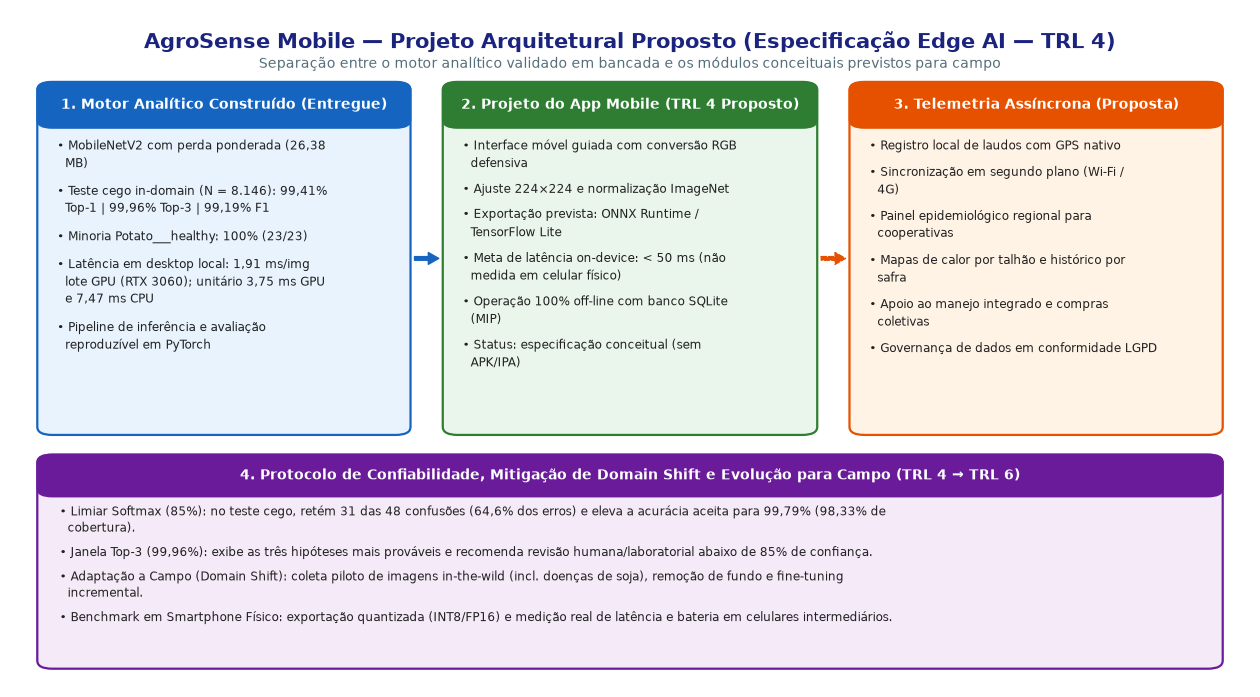

Figura salva: reports\figures\figura_arquitetura_edge_ai.png (539.9 KB, 300 DPI)


In [3]:
# 3. Geração da Figura: Projeto Arquitetural Proposto (Edge AI — TRL 4)
fig, ax = plt.subplots(figsize=(16, 8.8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
fig.patch.set_facecolor('white')

ax.text(0.5, 0.968, "AgroSense Mobile — Projeto Arquitetural Proposto (Especificação Edge AI — TRL 4)",
        ha='center', va='top', fontsize=15.0, fontweight='bold', color=PALETTE["navy"])
ax.text(0.5, 0.930, "Separação entre o motor analítico validado em bancada e os módulos conceituais previstos para campo",
        ha='center', va='top', fontsize=10.2, color=PALETTE["muted"])

y_top, h_top = 0.375, 0.515
draw_card(ax, 0.025, y_top, 0.295, h_top, "1. Motor Analítico Construído (Entregue)",
          PALETTE["blue"], "#E8F3FE", header_h=0.062, title_fs=10.4)
draw_bullets(ax, 0.038, y_top + h_top - 0.082, [
    "MobileNetV2 com perda ponderada (26,38 MB)",
    "Teste cego in-domain (N = 8.146): 99,41% Top-1 | 99,96% Top-3 | 99,19% F1",
    "Minoria Potato___healthy: 100% (23/23)",
    "Latência em desktop local: 1,91 ms/img lote GPU (RTX 3060); unitário 3,75 ms GPU e 7,47 ms CPU",
    "Pipeline de inferência e avaliação reproduzível em PyTorch"
], y_min=y_top + 0.018, wrap_chars=41, fs=8.8, line_gap=0.026, item_gap=0.015)

draw_card(ax, 0.352, y_top, 0.296, h_top, "2. Projeto do App Mobile (TRL 4 Proposto)",
          PALETTE["green"], "#EAF6EC", header_h=0.062, title_fs=10.4)
draw_bullets(ax, 0.365, y_top + h_top - 0.082, [
    "Interface móvel guiada com conversão RGB defensiva",
    "Ajuste 224×224 e normalização ImageNet",
    "Exportação prevista: ONNX Runtime / TensorFlow Lite",
    "Meta de latência on-device: < 50 ms (não medida em celular físico)",
    "Operação 100% off-line com banco SQLite (MIP)",
    "Status: especificação conceitual (sem APK/IPA)"
], y_min=y_top + 0.018, wrap_chars=41, fs=8.8, line_gap=0.026, item_gap=0.012)

draw_card(ax, 0.680, y_top, 0.295, h_top, "3. Telemetria Assíncrona (Proposta)",
          PALETTE["orange"], "#FFF3E6", header_h=0.062, title_fs=10.4)
draw_bullets(ax, 0.693, y_top + h_top - 0.082, [
    "Registro local de laudos com GPS nativo",
    "Sincronização em segundo plano (Wi-Fi / 4G)",
    "Painel epidemiológico regional para cooperativas",
    "Mapas de calor por talhão e histórico por safra",
    "Apoio ao manejo integrado e compras coletivas",
    "Governança de dados em conformidade LGPD"
], y_min=y_top + 0.018, wrap_chars=41, fs=8.8, line_gap=0.026, item_gap=0.013)

draw_arrow(ax, 0.324, y_top + h_top / 2, 0.348, y_top + h_top / 2, color=PALETTE["blue"])
draw_arrow(ax, 0.652, y_top + h_top / 2, 0.676, y_top + h_top / 2, color=PALETTE["orange"], ls='--')

y_bot, h_bot = 0.030, 0.310
draw_card(ax, 0.025, y_bot, 0.950, h_bot,
          "4. Protocolo de Confiabilidade, Mitigação de Domain Shift e Evolução para Campo (TRL 4 → TRL 6)",
          PALETTE["purple"], "#F4EAF8", header_h=0.056, title_fs=10.4)
draw_bullets(ax, 0.040, y_bot + h_bot - 0.072, [
    "Limiar Softmax (85%): no teste cego, retém 31 das 48 confusões (64,6% dos erros) e eleva a acurácia aceita para 99,79% (98,33% de cobertura).",
    "Janela Top-3 (99,96%): exibe as três hipóteses mais prováveis e recomenda revisão humana/laboratorial abaixo de 85% de confiança.",
    "Adaptação a Campo (Domain Shift): coleta piloto de imagens in-the-wild (incl. doenças de soja), remoção de fundo e fine-tuning incremental.",
    "Benchmark em Smartphone Físico: exportação quantizada (INT8/FP16) e medição real de latência e bateria em celulares intermediários."
], y_min=y_bot + 0.015, wrap_chars=136, fs=8.8, line_gap=0.024, item_gap=0.012)

out_arch = FIGURES_DIR / 'figura_arquitetura_edge_ai.png'
plt.savefig(out_arch, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {out_arch.relative_to(ETAPA4_DIR)} ({out_arch.stat().st_size/1024:.1f} KB, 300 DPI)")

---
## 4. Figura do Business Model Canvas (`figura_canvas_negocios.png`)

Sistematiza os 9 blocos do modelo de negócios B2B SaaS (OSTERWALDER; PIGNEUR, 2011) com proporções balanceadas e sem estouro de bordas.

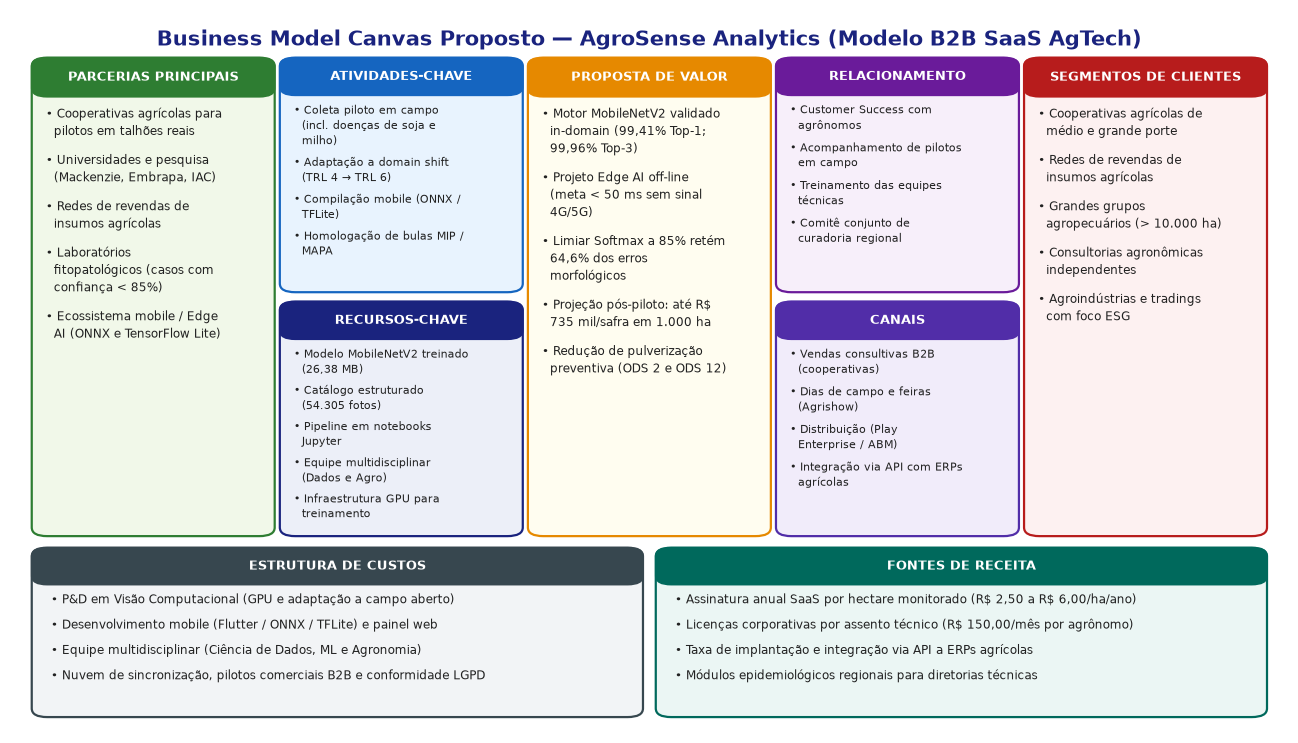

Figura salva: reports\figures\figura_canvas_negocios.png (663.8 KB, 300 DPI)


In [4]:
# 4. Geração da Figura: Business Model Canvas Proposto (Sem Overflow e Sem MathText em R$)
fig, ax = plt.subplots(figsize=(16.5, 9.4))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
fig.patch.set_facecolor('white')

ax.text(0.5, 0.972, "Business Model Canvas Proposto — AgroSense Analytics (Modelo B2B SaaS AgTech)",
        ha='center', va='top', fontsize=15.0, fontweight='bold', color=PALETTE["navy"])

y_u, h_u = 0.275, 0.655
w_col = 0.184
xs = [0.02 + i * (w_col + 0.010) for i in range(5)]

# Col 1: Parcerias
draw_card(ax, xs[0], y_u, w_col, h_u, "PARCERIAS PRINCIPAIS", PALETTE["green"], "#F1F8E9", header_h=0.048, title_fs=9.4)
draw_bullets(ax, xs[0] + 0.008, y_u + h_u - 0.066, [
    "Cooperativas agrícolas para pilotos em talhões reais",
    "Universidades e pesquisa (Mackenzie, Embrapa, IAC)",
    "Redes de revendas de insumos agrícolas",
    "Laboratórios fitopatológicos (casos com confiança < 85%)",
    "Ecossistema mobile / Edge AI (ONNX e TensorFlow Lite)"
], y_min=y_u + 0.015, wrap_chars=27, fs=8.3, line_gap=0.024, item_gap=0.016)

# Col 2: Atividades + Recursos
h_half = 0.318
draw_card(ax, xs[1], y_u + h_half + 0.019, w_col, h_half, "ATIVIDADES-CHAVE", PALETTE["blue"], "#E8F3FE", header_h=0.046, title_fs=9.4)
draw_bullets(ax, xs[1] + 0.008, y_u + h_u - 0.062, [
    "Coleta piloto em campo (incl. doenças de soja e milho)",
    "Adaptação a domain shift (TRL 4 → TRL 6)",
    "Compilação mobile (ONNX / TFLite)",
    "Homologação de bulas MIP / MAPA"
], y_min=y_u + h_half + 0.030, wrap_chars=27, fs=8.1, line_gap=0.021, item_gap=0.009)

draw_card(ax, xs[1], y_u, w_col, h_half, "RECURSOS-CHAVE", PALETTE["navy"], "#ECEFF8", header_h=0.046, title_fs=9.4)
draw_bullets(ax, xs[1] + 0.008, y_u + h_half - 0.062, [
    "Modelo MobileNetV2 treinado (26,38 MB)",
    "Catálogo estruturado (54.305 fotos)",
    "Pipeline em notebooks Jupyter",
    "Equipe multidisciplinar (Dados e Agro)",
    "Infraestrutura GPU para treinamento"
], y_min=y_u + 0.012, wrap_chars=27, fs=8.1, line_gap=0.021, item_gap=0.008)

# Col 3: Proposta de Valor
draw_card(ax, xs[2], y_u, w_col, h_u, "PROPOSTA DE VALOR", PALETTE["amber"], "#FFFDF0", header_h=0.048, title_fs=9.4)
draw_bullets(ax, xs[2] + 0.008, y_u + h_u - 0.066, [
    "Motor MobileNetV2 validado in-domain (99,41% Top-1; 99,96% Top-3)",
    "Projeto Edge AI off-line (meta < 50 ms sem sinal 4G/5G)",
    "Limiar Softmax a 85% retém 64,6% dos erros morfológicos",
    "Projeção pós-piloto: até R$ 735 mil/safra em 1.000 ha",
    "Redução de pulverização preventiva (ODS 2 e ODS 12)"
], y_min=y_u + 0.015, wrap_chars=27, fs=8.3, line_gap=0.024, item_gap=0.016)

# Col 4: Relacionamento + Canais
draw_card(ax, xs[3], y_u + h_half + 0.019, w_col, h_half, "RELACIONAMENTO", PALETTE["purple"], "#F7EFFA", header_h=0.046, title_fs=9.4)
draw_bullets(ax, xs[3] + 0.008, y_u + h_u - 0.062, [
    "Customer Success com agrônomos",
    "Acompanhamento de pilotos em campo",
    "Treinamento das equipes técnicas",
    "Comitê conjunto de curadoria regional"
], y_min=y_u + h_half + 0.030, wrap_chars=27, fs=8.1, line_gap=0.021, item_gap=0.010)

draw_card(ax, xs[3], y_u, w_col, h_half, "CANAIS", "#512DA8", "#F1ECFA", header_h=0.046, title_fs=9.4)
draw_bullets(ax, xs[3] + 0.008, y_u + h_half - 0.062, [
    "Vendas consultivas B2B (cooperativas)",
    "Dias de campo e feiras (Agrishow)",
    "Distribuição (Play Enterprise / ABM)",
    "Integração via API com ERPs agrícolas"
], y_min=y_u + 0.012, wrap_chars=27, fs=8.1, line_gap=0.021, item_gap=0.010)

# Col 5: Segmentos
draw_card(ax, xs[4], y_u, w_col, h_u, "SEGMENTOS DE CLIENTES", PALETTE["red"], "#FDF1F1", header_h=0.048, title_fs=9.4)
draw_bullets(ax, xs[4] + 0.008, y_u + h_u - 0.066, [
    "Cooperativas agrícolas de médio e grande porte",
    "Redes de revendas de insumos agrícolas",
    "Grandes grupos agropecuários (> 10.000 ha)",
    "Consultorias agronômicas independentes",
    "Agroindústrias e tradings com foco ESG"
], y_min=y_u + 0.015, wrap_chars=27, fs=8.3, line_gap=0.024, item_gap=0.016)

# Faixa inferior compacta
y_b, h_b = 0.025, 0.228
draw_card(ax, 0.02, y_b, 0.472, h_b, "ESTRUTURA DE CUSTOS", PALETTE["slate"], "#F2F4F6", header_h=0.045, title_fs=9.4)
draw_bullets(ax, 0.032, y_b + h_b - 0.060, [
    "P&D em Visão Computacional (GPU e adaptação a campo aberto)",
    "Desenvolvimento mobile (Flutter / ONNX / TFLite) e painel web",
    "Equipe multidisciplinar (Ciência de Dados, ML e Agronomia)",
    "Nuvem de sincronização, pilotos comerciais B2B e conformidade LGPD"
], y_min=y_b + 0.012, wrap_chars=74, fs=8.4, line_gap=0.024, item_gap=0.011)

draw_card(ax, 0.508, y_b, 0.472, h_b, "FONTES DE RECEITA", PALETTE["teal"], "#EBF6F4", header_h=0.045, title_fs=9.4)
draw_bullets(ax, 0.520, y_b + h_b - 0.060, [
    "Assinatura anual SaaS por hectare monitorado (R$ 2,50 a R$ 6,00/ha/ano)",
    "Licenças corporativas por assento técnico (R$ 150,00/mês por agrônomo)",
    "Taxa de implantação e integração via API a ERPs agrícolas",
    "Módulos epidemiológicos regionais para diretorias técnicas"
], y_min=y_b + 0.012, wrap_chars=74, fs=8.4, line_gap=0.024, item_gap=0.011)

out_canvas = FIGURES_DIR / 'figura_canvas_negocios.png'
plt.savefig(out_canvas, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {out_canvas.relative_to(ETAPA4_DIR)} ({out_canvas.stat().st_size/1024:.1f} KB, 300 DPI)")

---
## 5. Figura do Arco Narrativo em 3 Atos (`figura_storytelling_arco.png`)

Resume visualmente os **3 Atos** da apresentação executiva e do vídeo no YouTube com proporção vertical equilibrada e leitura limpa.

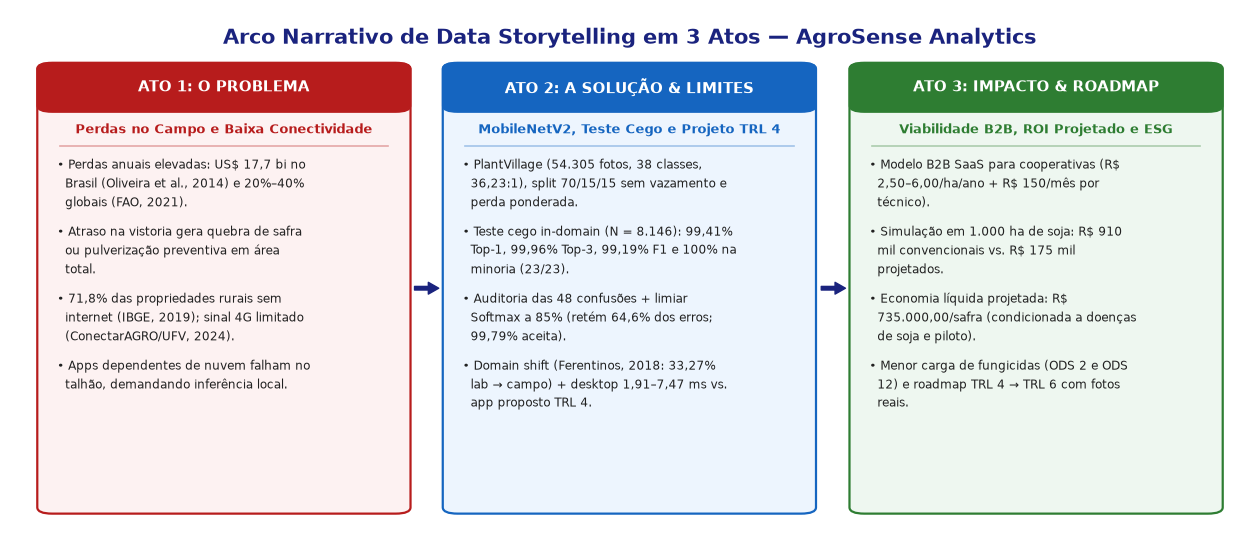

Figura salva: reports\figures\figura_storytelling_arco.png (418.7 KB, 300 DPI)


In [5]:
# 5. Geração da Figura: Arco Narrativo em 3 Atos (Sem Overflow)
fig, ax = plt.subplots(figsize=(16.0, 6.8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
fig.patch.set_facecolor('white')

ax.text(0.5, 0.965, "Arco Narrativo de Data Storytelling em 3 Atos — AgroSense Analytics",
        ha='center', va='top', fontsize=15.0, fontweight='bold', color=PALETTE["navy"])

acts = [
    {
        "x": 0.025, "header": "ATO 1: O PROBLEMA",
        "sub": "Perdas no Campo e Baixa Conectividade",
        "color": PALETTE["red"], "bg": "#FDF2F2",
        "bullets": [
            "Perdas anuais elevadas: US$ 17,7 bi no Brasil (Oliveira et al., 2014) e 20%–40% globais (FAO, 2021).",
            "Atraso na vistoria gera quebra de safra ou pulverização preventiva em área total.",
            "71,8% das propriedades rurais sem internet (IBGE, 2019); sinal 4G limitado (ConectarAGRO/UFV, 2024).",
            "Apps dependentes de nuvem falham no talhão, demandando inferência local."
        ]
    },
    {
        "x": 0.352, "header": "ATO 2: A SOLUÇÃO & LIMITES",
        "sub": "MobileNetV2, Teste Cego e Projeto TRL 4",
        "color": PALETTE["blue"], "bg": "#EDF5FE",
        "bullets": [
            "PlantVillage (54.305 fotos, 38 classes, 36,23:1), split 70/15/15 sem vazamento e perda ponderada.",
            "Teste cego in-domain (N = 8.146): 99,41% Top-1, 99,96% Top-3, 99,19% F1 e 100% na minoria (23/23).",
            "Auditoria das 48 confusões + limiar Softmax a 85% (retém 64,6% dos erros; 99,79% aceita).",
            "Domain shift (Ferentinos, 2018: 33,27% lab → campo) + desktop 1,91–7,47 ms vs. app proposto TRL 4."
        ]
    },
    {
        "x": 0.680, "header": "ATO 3: IMPACTO & ROADMAP",
        "sub": "Viabilidade B2B, ROI Projetado e ESG",
        "color": PALETTE["green"], "bg": "#EEF7F0",
        "bullets": [
            "Modelo B2B SaaS para cooperativas (R$ 2,50–6,00/ha/ano + R$ 150/mês por técnico).",
            "Simulação em 1.000 ha de soja: R$ 910 mil convencionais vs. R$ 175 mil projetados.",
            "Economia líquida projetada: R$ 735.000,00/safra (condicionada a doenças de soja e piloto).",
            "Menor carga de fungicidas (ODS 2 e ODS 12) e roadmap TRL 4 → TRL 6 com fotos reais."
        ]
    }
]

y_box, h_box, w_box = 0.04, 0.855, 0.295
for a in acts:
    draw_card(ax, a["x"], y_box, w_box, h_box, a["header"], a["color"], a["bg"], header_h=0.088, title_fs=10.8)
    ax.text(a["x"] + w_box / 2, y_box + h_box - 0.125, a["sub"],
            ha='center', va='center', fontsize=9.6, fontweight='bold', color=a["color"], zorder=4)
    ax.plot([a["x"] + 0.015, a["x"] + w_box - 0.015], [y_box + h_box - 0.155, y_box + h_box - 0.155],
            color=a["color"], alpha=0.35, lw=1.2, zorder=4)
    draw_bullets(ax, a["x"] + 0.013, y_box + h_box - 0.180, a["bullets"],
                 y_min=y_box + 0.015, wrap_chars=40, fs=8.7, line_gap=0.036, item_gap=0.020)

draw_arrow(ax, 0.324, y_box + h_box / 2, 0.348, y_box + h_box / 2, color=PALETTE["navy"])
draw_arrow(ax, 0.652, y_box + h_box / 2, 0.676, y_box + h_box / 2, color=PALETTE["navy"])

out_arc = FIGURES_DIR / 'figura_storytelling_arco.png'
plt.savefig(out_arc, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {out_arc.relative_to(ETAPA4_DIR)} ({out_arc.stat().st_size/1024:.1f} KB, 300 DPI)")

In [6]:
# 6. Verificação dos Arquivos de Figura Gerados
for fname in ['figura_arquitetura_edge_ai.png', 'figura_canvas_negocios.png', 'figura_storytelling_arco.png']:
    fp = FIGURES_DIR / fname
    assert fp.exists() and fp.stat().st_size > 50_000, f"Figura inválida: {fname}"
    print(f"[OK] {fp.relative_to(ETAPA4_DIR)} ({fp.stat().st_size/1024:.1f} KB)")

[OK] reports\figures\figura_arquitetura_edge_ai.png (539.9 KB)
[OK] reports\figures\figura_canvas_negocios.png (663.8 KB)
[OK] reports\figures\figura_storytelling_arco.png (418.7 KB)
